
# Duka Electronics Sales Exploration

**PLP Data Analysis – Week 3 Assignment**

**Student:** Nelly Mwangi

**Client:** Duka Electronics

**Period:** January–June 2026

## Objective

To explore Duka Electronics' sales data, identify branch and product performance, compare weekday and weekend sales, evaluate monthly revenue trends and provide actionable business recommendations.



## Executive Summary

- Duka Electronics recorded **KES 71,792,500** in total revenue from **1,000 orders** between January and June 2026.
- Nairobi was the highest-performing branch, generating **KES 26,106,100**, representing approximately **36.4%** of total revenue.
- Laptops generated the highest product revenue at **KES 41,535,000**, while tablets recorded the highest unit sales at **691 units**.
- April was the strongest month with **KES 13,518,300**, while June was the weakest at **KES 10,903,400**, making April approximately **24.0% higher** than June.
- The business received **83 Premium Online orders** from Nairobi and Mombasa, generating **KES 10,218,000** in revenue.


In [60]:

# Import the required libraries

import pandas as pd
import numpy as np

# Display all columns when viewing DataFrames
pd.set_option("display.max_columns", None)

# Display currency values without scientific notation
pd.set_option("display.float_format", "{:,.2f}".format)


In [61]:

# Load Duka Electronics sales data

sales = pd.read_csv(
    "duka_sales.csv",
    parse_dates=["order_date"]
)

# Display the first five records
sales.head()


,order_id,order_date,branch,product,quantity,channel,unit_price
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500



## Task 1: First-Five-Minutes Data Inspection

Before analysing the sales data, I conducted an initial inspection to understand the dataset's structure, data types, completeness, date coverage and key business categories.


In [62]:
sales.head()

,order_id,order_date,branch,product,quantity,channel,unit_price
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500


In [63]:
sales.tail()

,order_id,order_date,branch,product,quantity,channel,unit_price
995,1996,2026-03-04,Mombasa,Laptop,5,In-store,65000
996,1997,2026-03-06,Nairobi,Tablet,2,Phone order,28000
997,1998,2026-01-20,Nairobi,Laptop,3,Online,65000
998,1999,2026-03-02,Nairobi,Headphones,2,In-store,2500
999,2000,2026-01-30,Nakuru,Charger,4,In-store,1200


In [64]:
sales.shape

(1000, 7)

In [65]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   order_id    1000 non-null   int64         
 1   order_date  1000 non-null   datetime64[us]
 2   branch      1000 non-null   str           
 3   product     1000 non-null   str           
 4   quantity    1000 non-null   int64         
 5   channel     1000 non-null   str           
 6   unit_price  1000 non-null   int64         
dtypes: datetime64[us](1), int64(3), str(3)
memory usage: 54.8 KB


In [66]:
sales.describe()

,order_id,order_date,quantity,unit_price
count,"1,000.00",1000,"1,000.00","1,000.00"
mean,"1,500.50",2026-03-30 08:44:09.600000,3.01,"23,918.30"
min,"1,001.00",2026-01-01 00:00:00,1.00,"1,200.00"
25%,"1,250.75",2026-02-14 00:00:00,2.00,"2,500.00"
50%,"1,500.50",2026-03-29 00:00:00,3.00,"15,000.00"
75%,"1,750.25",2026-05-14 00:00:00,4.00,"28,000.00"
max,"2,000.00",2026-06-29 00:00:00,5.00,"65,000.00"
std,288.82,NaN,1.42,"23,908.79"


In [67]:
sales.isnull().sum()

order_id      0
order_date    0
branch        0
product       0
quantity      0
channel       0
unit_price    0
dtype: int64

In [68]:
sales.nunique()

order_id      1000
order_date     179
branch           5
product          5
quantity         5
channel          3
unit_price       5
dtype: int64

In [69]:
sales["branch"].value_counts()

branch
Nairobi    376
Mombasa    186
Nakuru     162
Kisumu     159
Eldoret    117
Name: count, dtype: int64

In [70]:
sales["branch"].value_counts(normalize=True).mul(100).round(1)

branch
Nairobi   37.60
Mombasa   18.60
Nakuru    16.20
Kisumu    15.90
Eldoret   11.70
Name: proportion, dtype: float64

In [71]:
sales["channel"].value_counts()

channel
In-store       579
Online         320
Phone order    101
Name: count, dtype: int64

In [72]:
sales["channel"].value_counts(normalize=True).mul(100).round(1)

channel
In-store      57.90
Online        32.00
Phone order   10.10
Name: proportion, dtype: float64

In [73]:
print("Earliest order:", sales["order_date"].min())
print("Latest order:", sales["order_date"].max())

Earliest order: 2026-01-01 00:00:00
Latest order: 2026-06-29 00:00:00



### Initial Inspection Findings

1. **Dataset structure:** The dataset contains 1,000 sales orders and 7 original columns.
2. **Data types:** The order_date column was correctly parsed as datetime, while order_id and quantity are integers. The categorical columns are stored as objects.
3. **Missing values:** All 7 columns contain 1,000 non-null records. No missing values were identified.
4. **Date coverage:** The dataset covers 1 January 2026 to 29 June 2026, representing the first half of 2026.
5. **Branch distribution:** Nairobi has the highest number of orders with 376 (37.6%), while Eldoret has the lowest with 117 (11.7%).
6. **Sales channels:** In-store orders account for 579 (57.9%), Online orders 320 (32.0%), and Phone orders 101 (10.1%).
7. **Product categories:** The dataset contains 5 product categories: Phone, Laptop, Headphones, Tablet and Charger.
8. **Overall assessment:** The dataset is complete and has consistent data types, making it suitable for further sales analysis.



## Task 2: Data Preparation and Feature Engineering

Feature engineering involves creating additional variables from existing data to make analysis easier and more meaningful.

For this analysis, I created five derived columns: revenue, month, weekday, is_weekend and price_band.


In [74]:

# 1. Calculate revenue for every order
sales["revenue"] = sales["quantity"] * sales["unit_price"]

# 2. Extract the month name
sales["month"] = sales["order_date"].dt.month_name()

# 3. Extract the weekday name
sales["weekday"] = sales["order_date"].dt.day_name()

# 4. Identify weekend orders
sales["is_weekend"] = sales["order_date"].dt.dayofweek >= 5

# 5. Classify products by price band
sales["price_band"] = np.where(
    sales["unit_price"] >= 28000,
    "Premium",
    "Value"
)

# Display the updated dataset
sales.head()


C:\Users\user\AppData\Local\Temp\ipykernel_5716\2631211205.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  sales["is_weekend"] = sales["order_date"].dt.dayofweek >= 5


,order_id,order_date,branch,product,quantity,channel,unit_price,revenue,month,weekday,is_weekend,price_band
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000,45000,June,Wednesday,False,Value
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000,260000,February,Monday,False,Premium
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000,140000,January,Monday,False,Premium
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500,12500,April,Sunday,True,Value
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500,7500,March,Saturday,True,Value


In [75]:
# Check the number of records in each derived category

print("Revenue summary:")
print(sales["revenue"].describe())

print("\nOrders by month:")
print(sales["month"].value_counts())

print("\nOrders by weekday:")
print(sales["weekday"].value_counts())

print("\nWeekend classification:")
print(sales["is_weekend"].value_counts())

print("\nPrice band classification:")
print(sales["price_band"].value_counts())

Revenue summary:
count     1,000.00
mean     71,792.50
std      84,180.92
min       1,200.00
25%       6,000.00
50%      45,000.00
75%     112,000.00
max     325,000.00
Name: revenue, dtype: float64

Orders by month:
month
March       186
January     173
April       167
June        162
February    159
May         153
Name: count, dtype: int64

Orders by weekday:
weekday
Friday       166
Sunday       145
Thursday     145
Monday       140
Wednesday    137
Tuesday      135
Saturday     132
Name: count, dtype: int64

Weekend classification:
is_weekend
False    723
True     277
Name: count, dtype: int64

Price band classification:
price_band
Value      565
Premium    435
Name: count, dtype: int64


In [76]:
# Confirm all required columns exist

sales.columns

Index(['order_id', 'order_date', 'branch', 'product', 'quantity', 'channel',
       'unit_price', 'revenue', 'month', 'weekday', 'is_weekend',
       'price_band'],
      dtype='str')


## Task 3: Branch Performance – Revenue and Order Rankings

The objective is to evaluate the performance of the five Duka Electronics branches by comparing their total revenue and number of orders.


In [77]:

# Calculate total revenue for each branch

branch_revenue = (
    sales.groupby("branch")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

branch_revenue


branch
Nairobi    26106100
Mombasa    14003700
Nakuru     11970400
Kisumu     10868100
Eldoret     8844200
Name: revenue, dtype: int64

In [78]:

# Count the number of orders per branch

branch_orders = (
    sales.groupby("branch")["order_id"]
    .count()
    .sort_values(ascending=False)
)

branch_orders


branch
Nairobi    376
Mombasa    186
Nakuru     162
Kisumu     159
Eldoret    117
Name: order_id, dtype: int64

In [79]:

# Combine branch revenue and order counts

branch_comparison = pd.DataFrame({
    "Total Revenue (KES)": branch_revenue,
    "Number of Orders": branch_orders
})

branch_comparison


,Total Revenue (KES),Number of Orders
branch,,
Nairobi,26106100,376
Mombasa,14003700,186
Nakuru,11970400,162
Kisumu,10868100,159
Eldoret,8844200,117


In [80]:

# Calculate each branch's percentage contribution

branch_comparison["Revenue Share (%)"] = (
    branch_comparison["Total Revenue (KES)"]
    / sales["revenue"].sum() * 100
).round(2)

branch_comparison


,Total Revenue (KES),Number of Orders,Revenue Share (%)
branch,,,
Nairobi,26106100,376,36.36
Mombasa,14003700,186,19.51
Nakuru,11970400,162,16.67
Kisumu,10868100,159,15.14
Eldoret,8844200,117,12.32



### Business Interpretation

The branch revenue and order rankings provide two different measures of business performance.

Nairobi is the leading branch in terms of total revenue, contributing approximately 36.4% of overall sales revenue. It also has the highest order volume.

Revenue and order rankings measure different aspects of performance. Revenue measures the monetary value generated, while order count measures customer purchasing activity. A branch can receive many orders but generate less revenue if its customers purchase lower-priced products or smaller quantities.

Management should therefore evaluate branches using both revenue and order volume rather than relying on only one performance indicator.



## Task 4: Product Performance – Revenue and Units Sold

This analysis evaluates product performance using two measures: total revenue generated and total units sold. Comparing these measures helps identify products that contribute the most money and products that experience the highest sales volume.


In [81]:

# Group sales by product and calculate performance metrics

product_performance = (
    sales.groupby("product")
    .agg(
        total_revenue=("revenue", "sum"),
        units_sold=("quantity", "sum"),
        number_of_orders=("order_id", "count")
    )
)

# Rank products by revenue
product_by_revenue = product_performance.sort_values(
    by="total_revenue",
    ascending=False
)

product_by_revenue


,total_revenue,units_sold,number_of_orders
product,,,
Laptop,41535000,639,220
Tablet,19348000,691,215
Phone,8880000,592,194
Headphones,1387500,555,187
Charger,642000,535,184


In [82]:

top_three_revenue = product_by_revenue.head(3)

top_three_revenue


,total_revenue,units_sold,number_of_orders
product,,,
Laptop,41535000,639,220
Tablet,19348000,691,215
Phone,8880000,592,194


In [83]:

top_three_units = product_performance.sort_values(
    by="units_sold",
    ascending=False
).head(3)

top_three_units


,total_revenue,units_sold,number_of_orders
product,,,
Tablet,19348000,691,215
Laptop,41535000,639,220
Phone,8880000,592,194


In [84]:

# Compare the two rankings

product_comparison = pd.DataFrame({
    "Revenue Rank": product_performance["total_revenue"].rank(
        ascending=False,
        method="min"
    ).astype(int),
    "Units Sold Rank": product_performance["units_sold"].rank(
        ascending=False,
        method="min"
    ).astype(int),
    "Total Revenue (KES)": product_performance["total_revenue"],
    "Units Sold": product_performance["units_sold"]
})

product_comparison.sort_values("Revenue Rank")


,Revenue Rank,Units Sold Rank,Total Revenue (KES),Units Sold
product,,,,
Laptop,1,2,41535000,639
Tablet,2,1,19348000,691
Phone,3,3,8880000,592
Headphones,4,4,1387500,555
Charger,5,5,642000,535



### Product Performance Findings

Laptops generated the highest revenue at KES 41,535,000 from 639 units sold. Tablets ranked second in revenue at KES 19,348,000 but recorded the highest sales volume at 691 units.

Phones ranked third in both revenue and units sold, generating KES 8,880,000 from 592 units.

The difference between the rankings is mainly explained by product prices. Laptops have a higher unit price of KES 65,000, allowing them to generate more revenue despite selling fewer units than tablets. Tablets have a unit price of KES 28,000 and therefore require a higher sales volume to generate comparable revenue.

Management should maintain laptop availability because of its strong revenue contribution while monitoring tablet demand because it has the highest unit sales.



## Task 5: Weekend vs Weekday Sales Performance

This analysis compares weekday and weekend sales to determine whether customer purchasing behaviour differs between the two periods.

The comparison uses order count, total revenue and average order revenue.


In [85]:

# Group sales by weekend classification

weekend_performance = (
    sales.groupby("is_weekend")
    .agg(
        number_of_orders=("order_id", "count"),
        total_revenue=("revenue", "sum"),
        average_order_revenue=("revenue", "mean")
    )
)

# Give the categories readable names
weekend_performance.index = [
    "Weekday" if value == False else "Weekend"
    for value in weekend_performance.index
]

# Round average revenue
weekend_performance["average_order_revenue"] = (
    weekend_performance["average_order_revenue"].round(2)
)

weekend_performance


,number_of_orders,total_revenue,average_order_revenue
Weekday,723,51856200,"71,723.65"
Weekend,277,19936300,"71,972.20"


In [86]:

# Compare weekend and weekday performance

weekday_revenue = weekend_performance.loc[
    "Weekday", "total_revenue"
]

weekend_revenue = weekend_performance.loc[
    "Weekend", "total_revenue"
]

weekday_orders = weekend_performance.loc[
    "Weekday", "number_of_orders"
]

weekend_orders = weekend_performance.loc[
    "Weekend", "number_of_orders"
]

weekday_average = weekend_performance.loc[
    "Weekday", "average_order_revenue"
]

weekend_average = weekend_performance.loc[
    "Weekend", "average_order_revenue"
]

print(
    "Weekend revenue difference (%):",
    round((weekend_revenue - weekday_revenue) / weekday_revenue * 100, 2)
)

print(
    "Weekend order average difference (%):",
    round((weekend_average - weekday_average) / weekday_average * 100, 2)
)


Weekend revenue difference (%): -61.55
Weekend order average difference (%): 0.35



### Weekend vs Weekday Findings

Weekdays recorded 723 orders and generated KES 51,856,200 in revenue, while weekends recorded 277 orders and generated KES 19,936,300.

Weekdays therefore contributed approximately 72.2% of total revenue, compared with 27.8% for weekends.

However, average order revenue was slightly higher during weekends at KES 71,972, compared with KES 71,724 on weekdays. This represents an increase of approximately 0.35%.

The results indicate that Duka Electronics receives substantially more orders during weekdays, but the average value of an individual order is almost identical across both periods.

Management could investigate targeted weekend promotions to increase weekend order volume without relying solely on discounts.



## Task 6: Monthly Revenue Performance

This analysis evaluates monthly sales revenue from January to June 2026. The objective is to identify the best-performing and weakest months and quantify the difference in revenue between them.


In [87]:

# Define the correct chronological order of months

month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June"
]

# Calculate monthly performance
monthly_performance = (
    sales.groupby("month")
    .agg(
        number_of_orders=("order_id", "count"),
        total_revenue=("revenue", "sum"),
        average_order_revenue=("revenue", "mean")
    )
    .reindex(month_order)
)

monthly_performance["average_order_revenue"] = (
    monthly_performance["average_order_revenue"].round(2)
)

monthly_performance


,number_of_orders,total_revenue,average_order_revenue
month,,,
January,173,11786600,"68,130.64"
February,159,11772000,"74,037.74"
March,186,12396800,"66,649.46"
April,167,13518300,"80,947.90"
May,153,11415400,"74,610.46"
June,162,10903400,"67,304.94"


In [88]:

# Find the month with the highest revenue
best_month = monthly_performance["total_revenue"].idxmax()

# Find the month with the lowest revenue
worst_month = monthly_performance["total_revenue"].idxmin()

best_revenue = monthly_performance.loc[
    best_month, "total_revenue"
]

worst_revenue = monthly_performance.loc[
    worst_month, "total_revenue"
]

# Calculate percentage difference relative to the worst month
percentage_difference = (
    (best_revenue - worst_revenue) / worst_revenue
) * 100

print("Best month:", best_month)
print("Best month revenue: KES", f"{best_revenue:,.0f}")

print("\nWorst month:", worst_month)
print("Worst month revenue: KES", f"{worst_revenue:,.0f}")

print(
    "\nPercentage difference:",
    round(percentage_difference, 2), "%"
)


Best month: April
Best month revenue: KES 13,518,300

Worst month: June
Worst month revenue: KES 10,903,400

Percentage difference: 23.98 %


Matplotlib is building the font cache; this may take a moment.


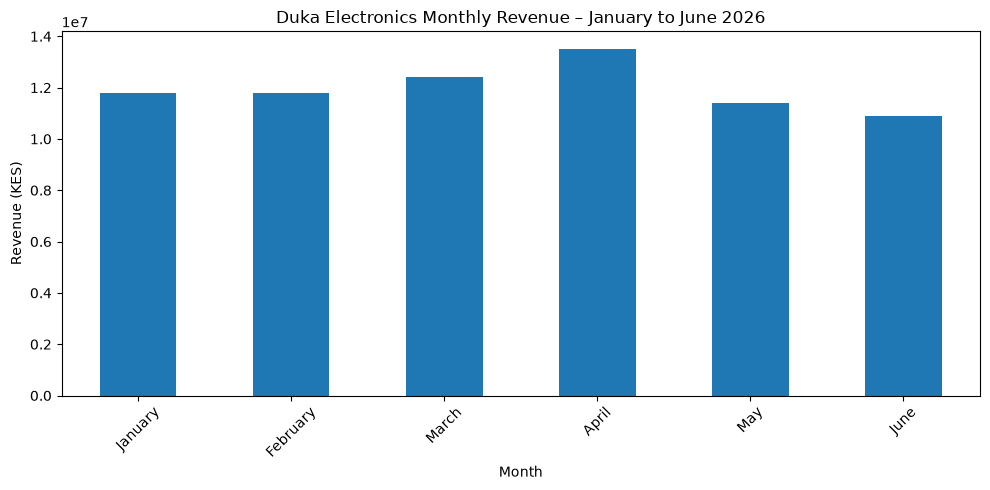

In [92]:

import matplotlib.pyplot as plt

# Create monthly revenue chart

monthly_performance["total_revenue"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Duka Electronics Monthly Revenue – January to June 2026"
)

plt.xlabel("Month")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### Monthly Revenue Findings

April was the strongest month, generating KES 13,518,300 in revenue from 167 orders.

June was the weakest month, generating KES 10,903,400 from 162 orders.

April's revenue was approximately 23.98% higher than June's revenue, using June as the comparison baseline.

The difference suggests that monthly revenue performance is not determined by order volume alone. April generated more revenue despite having only five more orders than June, indicating differences in the value of products purchased and quantities sold.

Management should investigate the product mix and sales activities during April to identify practices that could help improve performance in weaker months.



## Task 7: Premium Online Orders – Nairobi and Mombasa

The objective is to identify Premium orders placed through the Online channel in Nairobi and Mombasa.

Premium products have a unit price of KES 28,000 or more. The analysis will establish the number of qualifying orders and their total revenue.


In [97]:

# Filter Premium online orders from Nairobi and Mombasa

premium_online = sales[
    (sales["price_band"] == "Premium") &
    (sales["channel"] == "Online") &
    (sales["branch"].isin(["Nairobi", "Mombasa"]))
].copy()

# Display the filtered records
premium_online.head()


,order_id,order_date,branch,product,quantity,channel,unit_price,revenue,month,weekday,is_weekend,price_band
6,1007,2026-01-15,Nairobi,Laptop,2,Online,65000,130000,January,Thursday,False,Premium
13,1014,2026-06-12,Nairobi,Tablet,3,Online,28000,84000,June,Friday,False,Premium
32,1033,2026-04-29,Nairobi,Laptop,2,Online,65000,130000,April,Wednesday,False,Premium
35,1036,2026-03-02,Nairobi,Laptop,4,Online,65000,260000,March,Monday,False,Premium
39,1040,2026-02-10,Mombasa,Laptop,5,Online,65000,325000,February,Tuesday,False,Premium


In [98]:

# Calculate number of qualifying orders
premium_order_count = len(premium_online)

# Calculate total revenue
premium_total_revenue = premium_online["revenue"].sum()

print("Number of Premium Online Orders:", premium_order_count)

print(
    "Total Revenue: KES",
    f"{premium_total_revenue:,.0f}"
)


Number of Premium Online Orders: 83
Total Revenue: KES 10,218,000


In [99]:

# Break down Premium Online orders by branch

premium_branch_summary = (
    premium_online.groupby("branch")
    .agg(
        number_of_orders=("order_id", "count"),
        total_revenue=("revenue", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

premium_branch_summary


,number_of_orders,total_revenue
branch,,
Nairobi,50,6522000
Mombasa,33,3696000


In [100]:

# Create the outputs directory if it does not exist

import os

os.makedirs("outputs", exist_ok=True)

# Export without the DataFrame index
premium_online.to_csv(
    "outputs/premium_online_coast_capital.csv",
    index=False
)

print("Premium Online dataset exported successfully.")


Premium Online dataset exported successfully.



### Premium Online Sales Findings

The analysis identified 83 Premium Online orders from Nairobi and Mombasa, generating a combined revenue of KES 10,218,000.

These orders represent an important segment of the business because they combine higher-priced products with online purchasing.

Management should monitor this customer segment, maintain sufficient stock of Premium products and evaluate opportunities to grow online sales in both branches.



## Task 8: Excel Analysis and Validation

The branch revenue summary was reproduced in Microsoft Excel using SUMIFS. The region column was added using XLOOKUP, and a PivotTable was created to summarise revenue by branch and sales channel.

The Excel branch revenue table and PivotTable both produced a grand total of KES 71,792,500, matching the pandas calculation.

The analysis confirms that Nairobi generated the highest branch revenue at KES 26,106,100, while Eldoret generated the lowest at KES 8,844,200.

The agreement between pandas and Excel demonstrates that the spreadsheet calculations are consistent with the Python analysis.


In [101]:

# Validate the pandas branch revenue results

pandas_total = sales["revenue"].sum()

pandas_branch_summary = (
    sales.groupby("branch")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Pandas total revenue: KES", f"{pandas_total:,.0f}")

print("\nPandas branch revenue:")
print(pandas_branch_summary)

# Check that all branch revenue adds up correctly
assert pandas_branch_summary.sum() == pandas_total

print("\nValidation successful: pandas calculations are consistent.")


Pandas total revenue: KES 71,792,500

Pandas branch revenue:
branch
Nairobi    26106100
Mombasa    14003700
Nakuru     11970400
Kisumu     10868100
Eldoret     8844200
Name: revenue, dtype: int64

Validation successful: pandas calculations are consistent.
